In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

print("Everything is working!")

Everything is working!


In [ ]:
print(123)

123


In [ ]:
# loading a dataset into a pandas dataframe

titanic = pd .read_csv('C:/Users/warmu/OneDrive/Desktop/titanic2 (2)/train.csv')
titanic.head()

titanic.info()  # to get the information about the dataset

titanic.columns # to get the columns of the dataset atributes

titanic.shape # to get the number of rows and columns in the dataset



<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


(891, 12)

In [ ]:
titanic.nunique() # to get the number of unique values in each column
#///////////////////////////////////////////////
print("Surived : ", titanic["Survived"].unique()) # to get the unique values in the Survived column
print("Pclass : ", titanic["Pclass"].unique())
print("Sex : ", titanic["Sex"].unique())
print("Age : ", titanic["Age"].unique())
print("SibSp : ", titanic["SibSp"].unique())
print("Parch : ", titanic["Parch"].unique())
print("Ticket : ", titanic["Ticket"].unique())
print("Fare : ", titanic["Fare"].unique())
print("Cabin : ", titanic["Cabin"].unique())
print("Embarked : ", titanic["Embarked"].unique())  

 




Surived :  [0 1]
Pclass :  [3 1 2]
Sex :  <StringArray>
['male', 'female']
Length: 2, dtype: str
Age :  [22.   38.   26.   35.     nan 54.    2.   27.   14.    4.   58.   20.
 39.   55.   31.   34.   15.   28.    8.   19.   40.   66.   42.   21.
 18.    3.    7.   49.   29.   65.   28.5   5.   11.   45.   17.   32.
 16.   25.    0.83 30.   33.   23.   24.   46.   59.   71.   37.   47.
 14.5  70.5  32.5  12.    9.   36.5  51.   55.5  40.5  44.    1.   61.
 56.   50.   36.   45.5  20.5  62.   41.   52.   63.   23.5   0.92 43.
 60.   10.   64.   13.   48.    0.75 53.   57.   80.   70.   24.5   6.
  0.67 30.5   0.42 34.5  74.  ]
SibSp :  [1 0 3 4 2 5 8]
Parch :  [0 1 2 5 3 4 6]
Ticket :  <StringArray>
[       'A/5 21171',         'PC 17599', 'STON/O2. 3101282',
           '113803',           '373450',           '330877',
            '17463',           '349909',           '347742',
           '237736',
 ...
           '349212',           '349217',           '349257',
             '7552', 'C

In [ ]:
titanic.duplicated().sum()
titanic.drop_duplicates(inplace=True)

In [ ]:
## if number of missing number in a column is large w.r.t total value them drppping then column is a suitable strategy

titanic.drop("Cabin", axis=1, inplace=True)

print(titanic.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='str')


In [ ]:
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
dtype: int64

In [ ]:
mean_age = titanic["Age"].mean()

titanic["Age"].replace(np.nan, mean_age, inplace=True)

print(titanic.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
dtype: int64


In [ ]:
# print(titanic["Embarked"].mode()[0])



In [ ]:
titanic.Embarked.mode()

0    S
Name: Embarked, dtype: str

In [ ]:
mode_embarked = titanic["Embarked"].mode()[0]

titanic["Embarked"].replace(np.nan, mode_embarked, inplace=True)

print(titanic.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
dtype: int64


In [ ]:
titanic.head(1)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,S


In [ ]:
titanic["fimaly_member"] = titanic.SibSp + titanic.Parch
titanic.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,fimaly_member
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,0


In [ ]:
titanic.drop(["SibSp", "Parch"], axis=1, inplace=True)

titanic.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,Ticket,Fare,Embarked,fimaly_member
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,A/5 21171,7.2500,S,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,PC 17599,71.2833,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,STON/O2. 3101282,7.9250,S,0


In [ ]:
# ## to check of many are servived and how are dead

# plt.figure(figsize=(8, 5))

# plt.hist(titanic["Age"], bins=20)

# plt.title("Age Distribution")
# plt.xlabel("Age")
# plt.ylabel("Number of Passengers")

# plt.show()

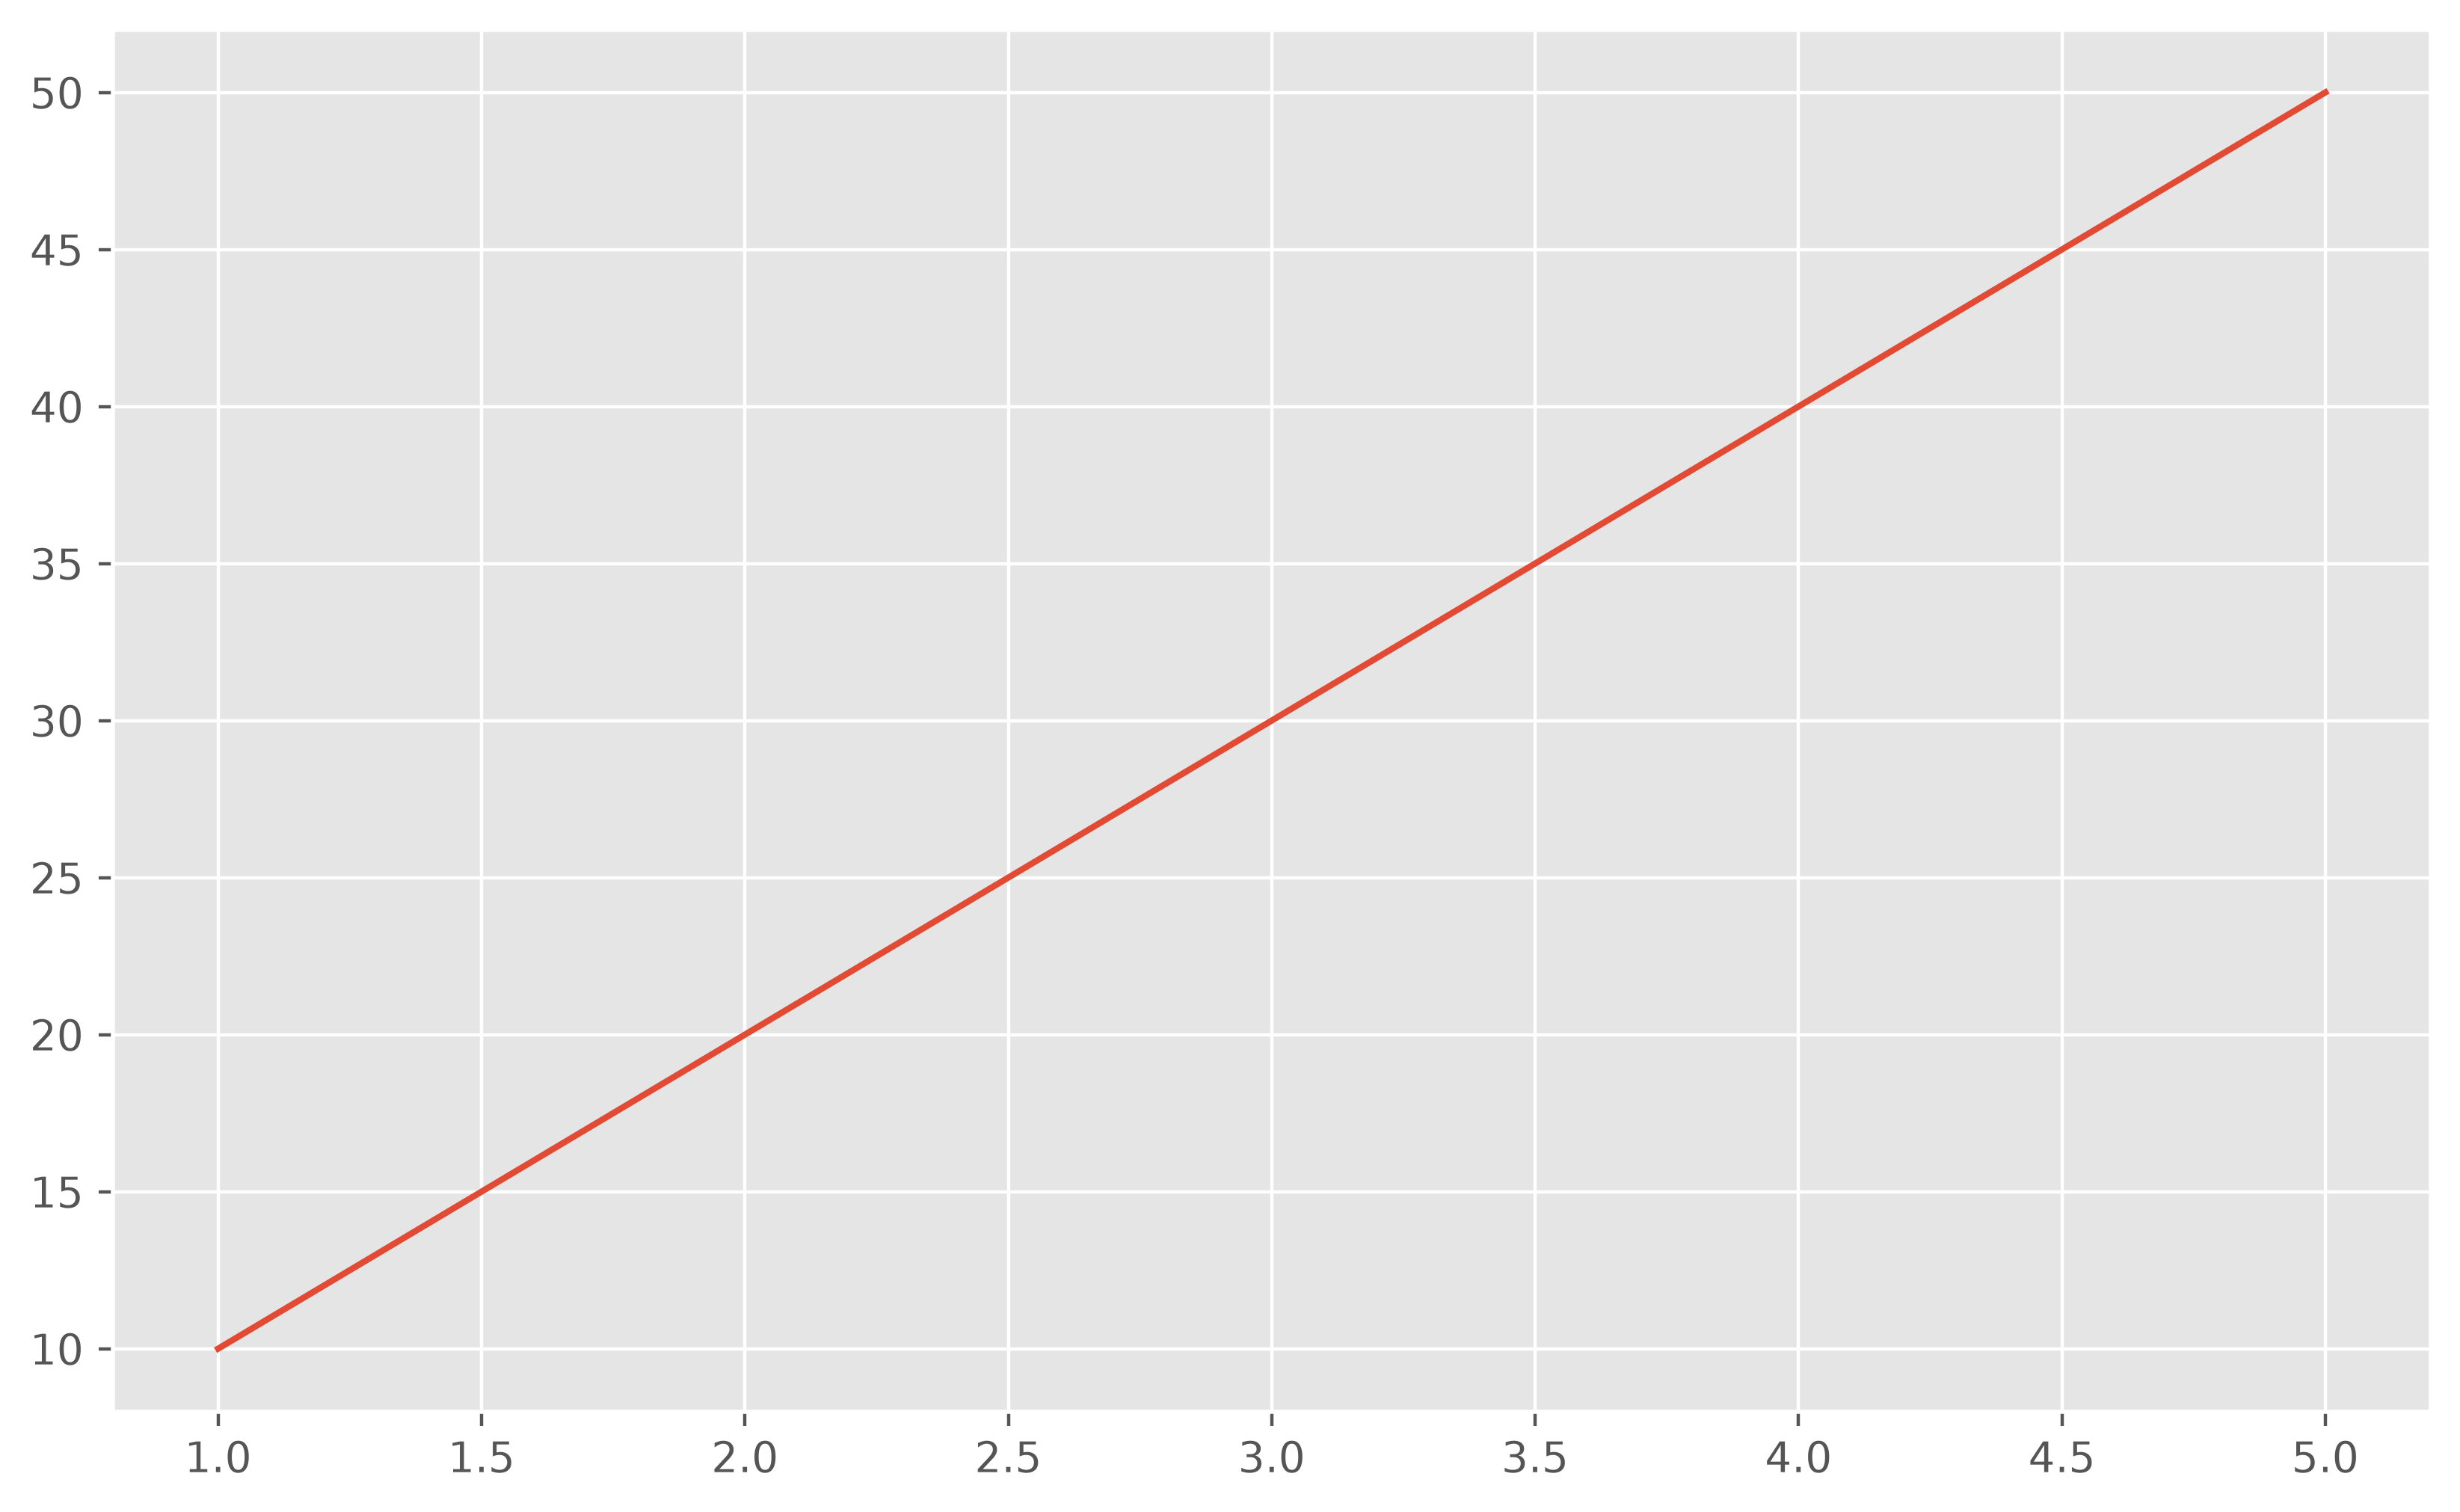

In [ ]:
plt.figure(figsize=(10, 6), dpi=400)
x= [1,2,3,4,5]
y= [10,20,30,40,50]
plt.plot(x,y)
plt.show()

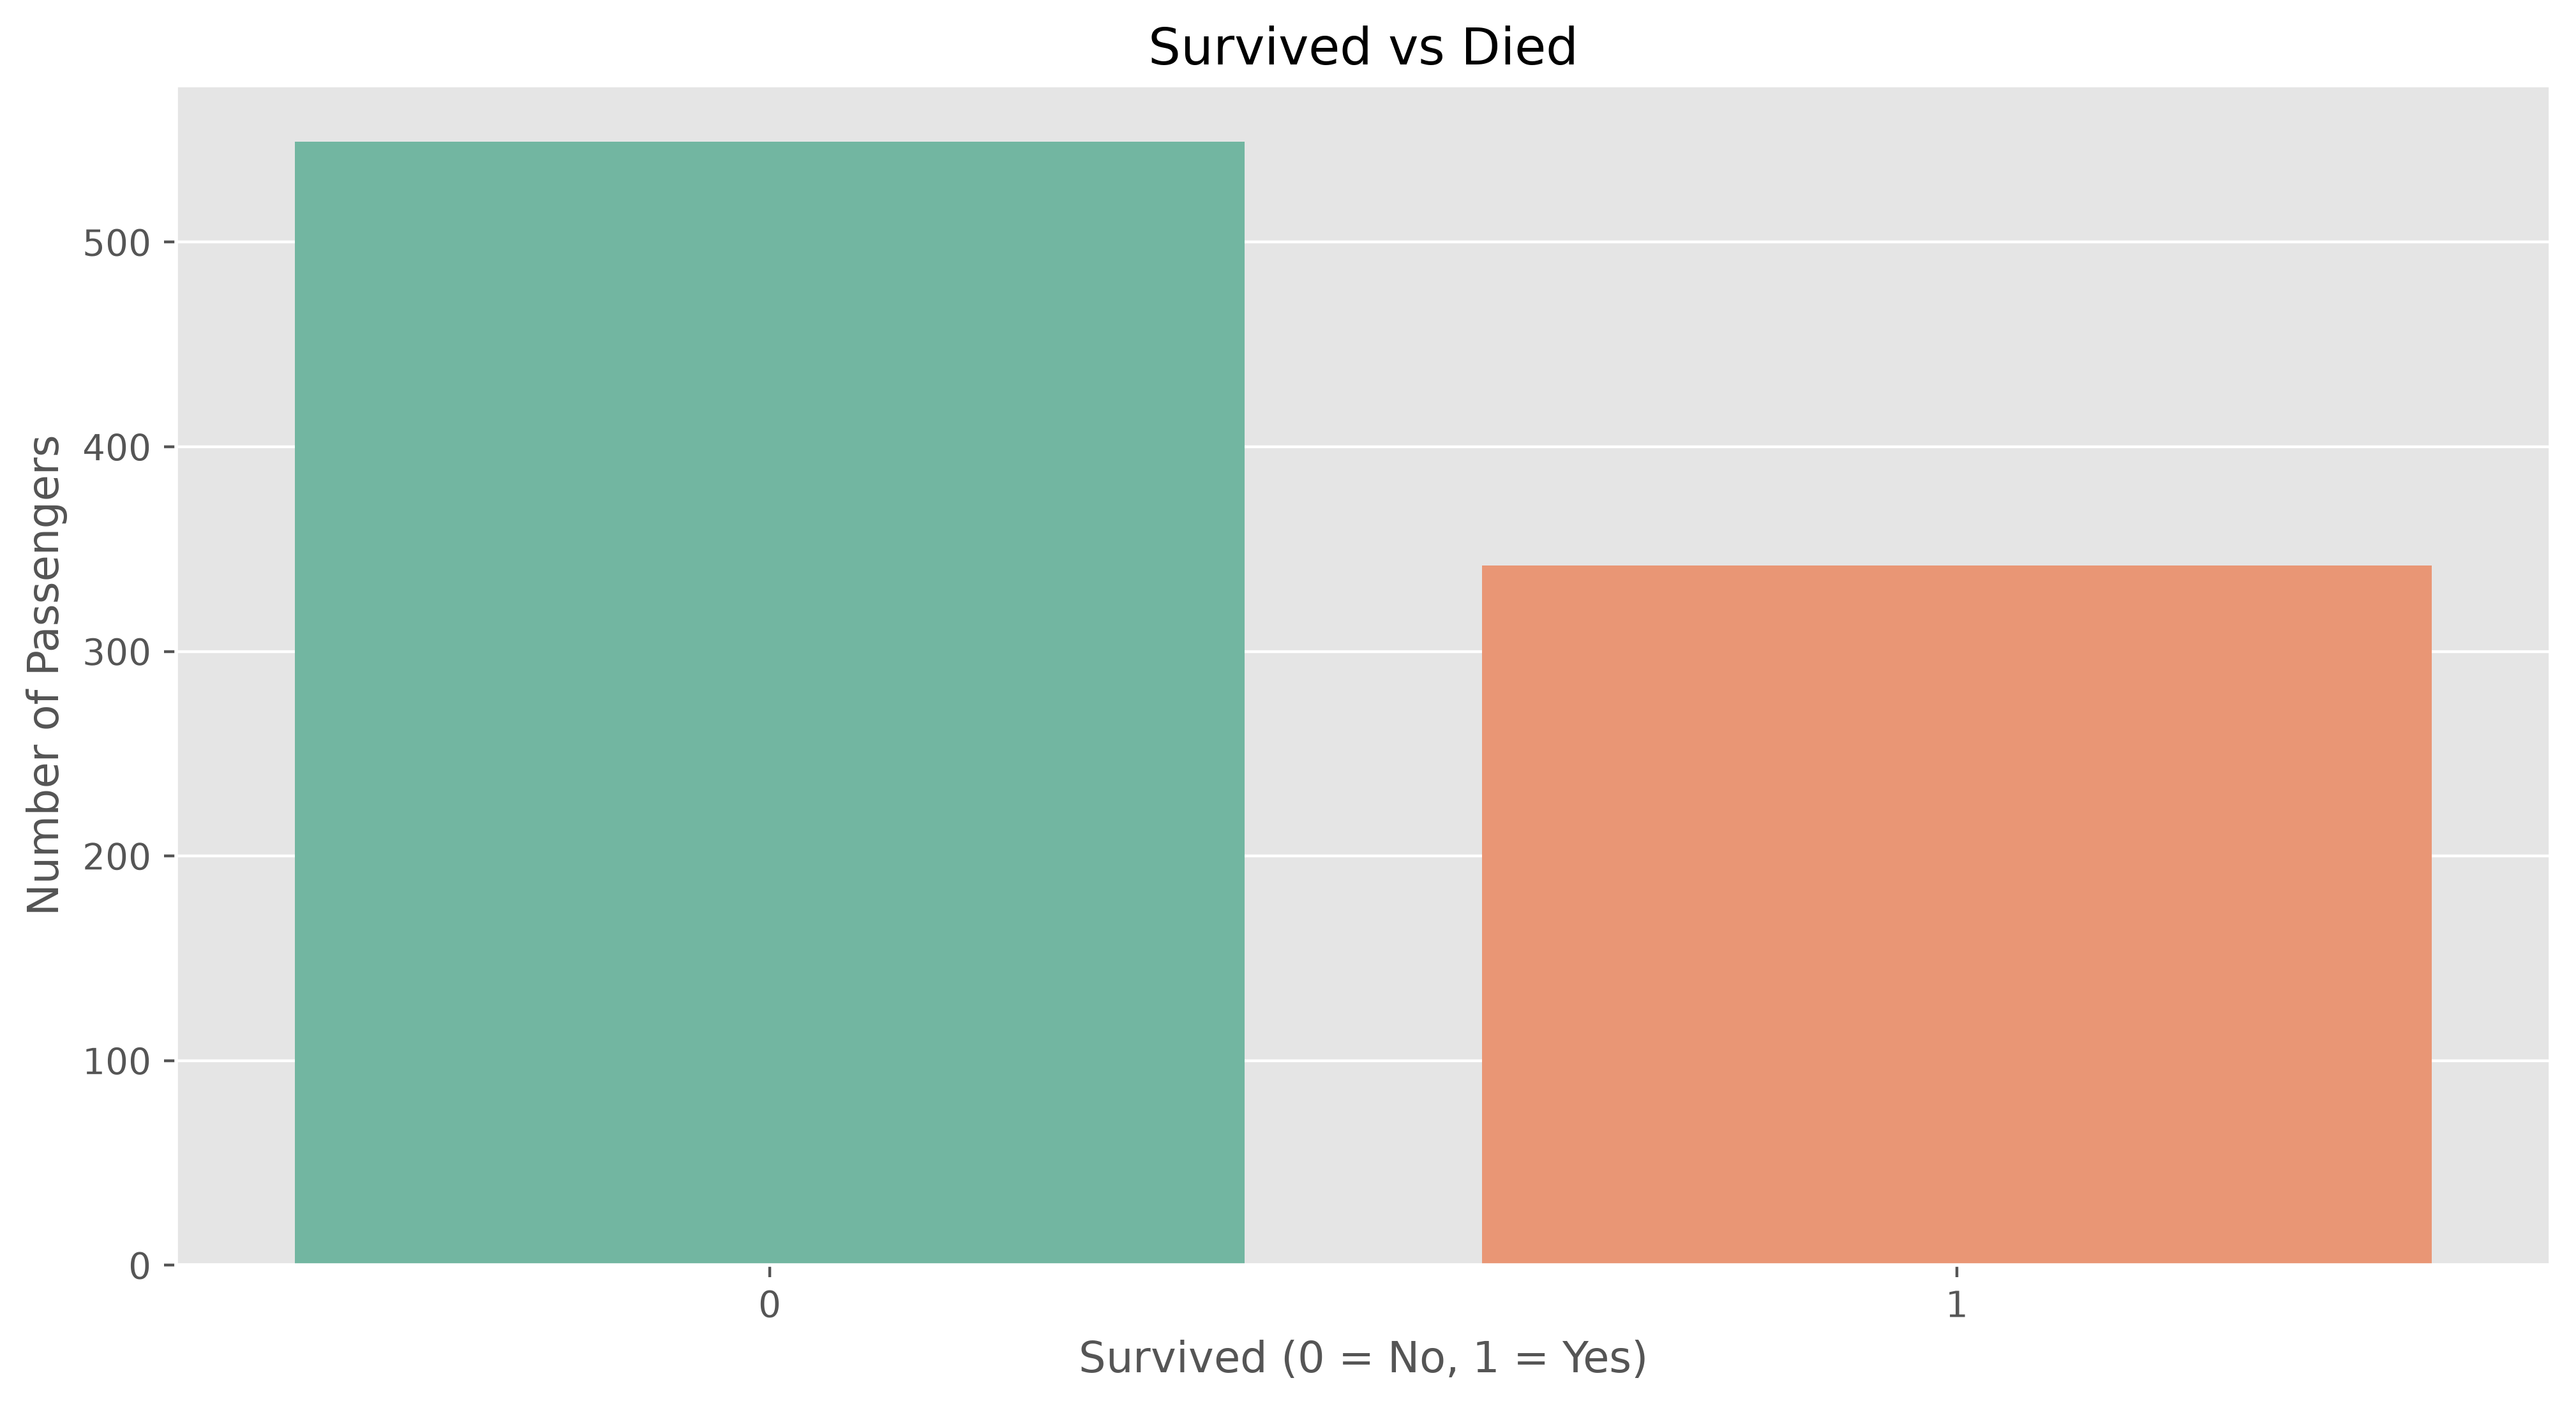

In [ ]:
# To check how many survived and how many died

plt.figure(figsize=(12, 6), dpi=400)

sns.countplot(x="Survived", data=titanic, palette="Set2")

plt.title("Survived vs Died")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

In [ ]:
titanic.Survived.value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [ ]:
titanic.Survived.value_counts(normalize=True)*100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

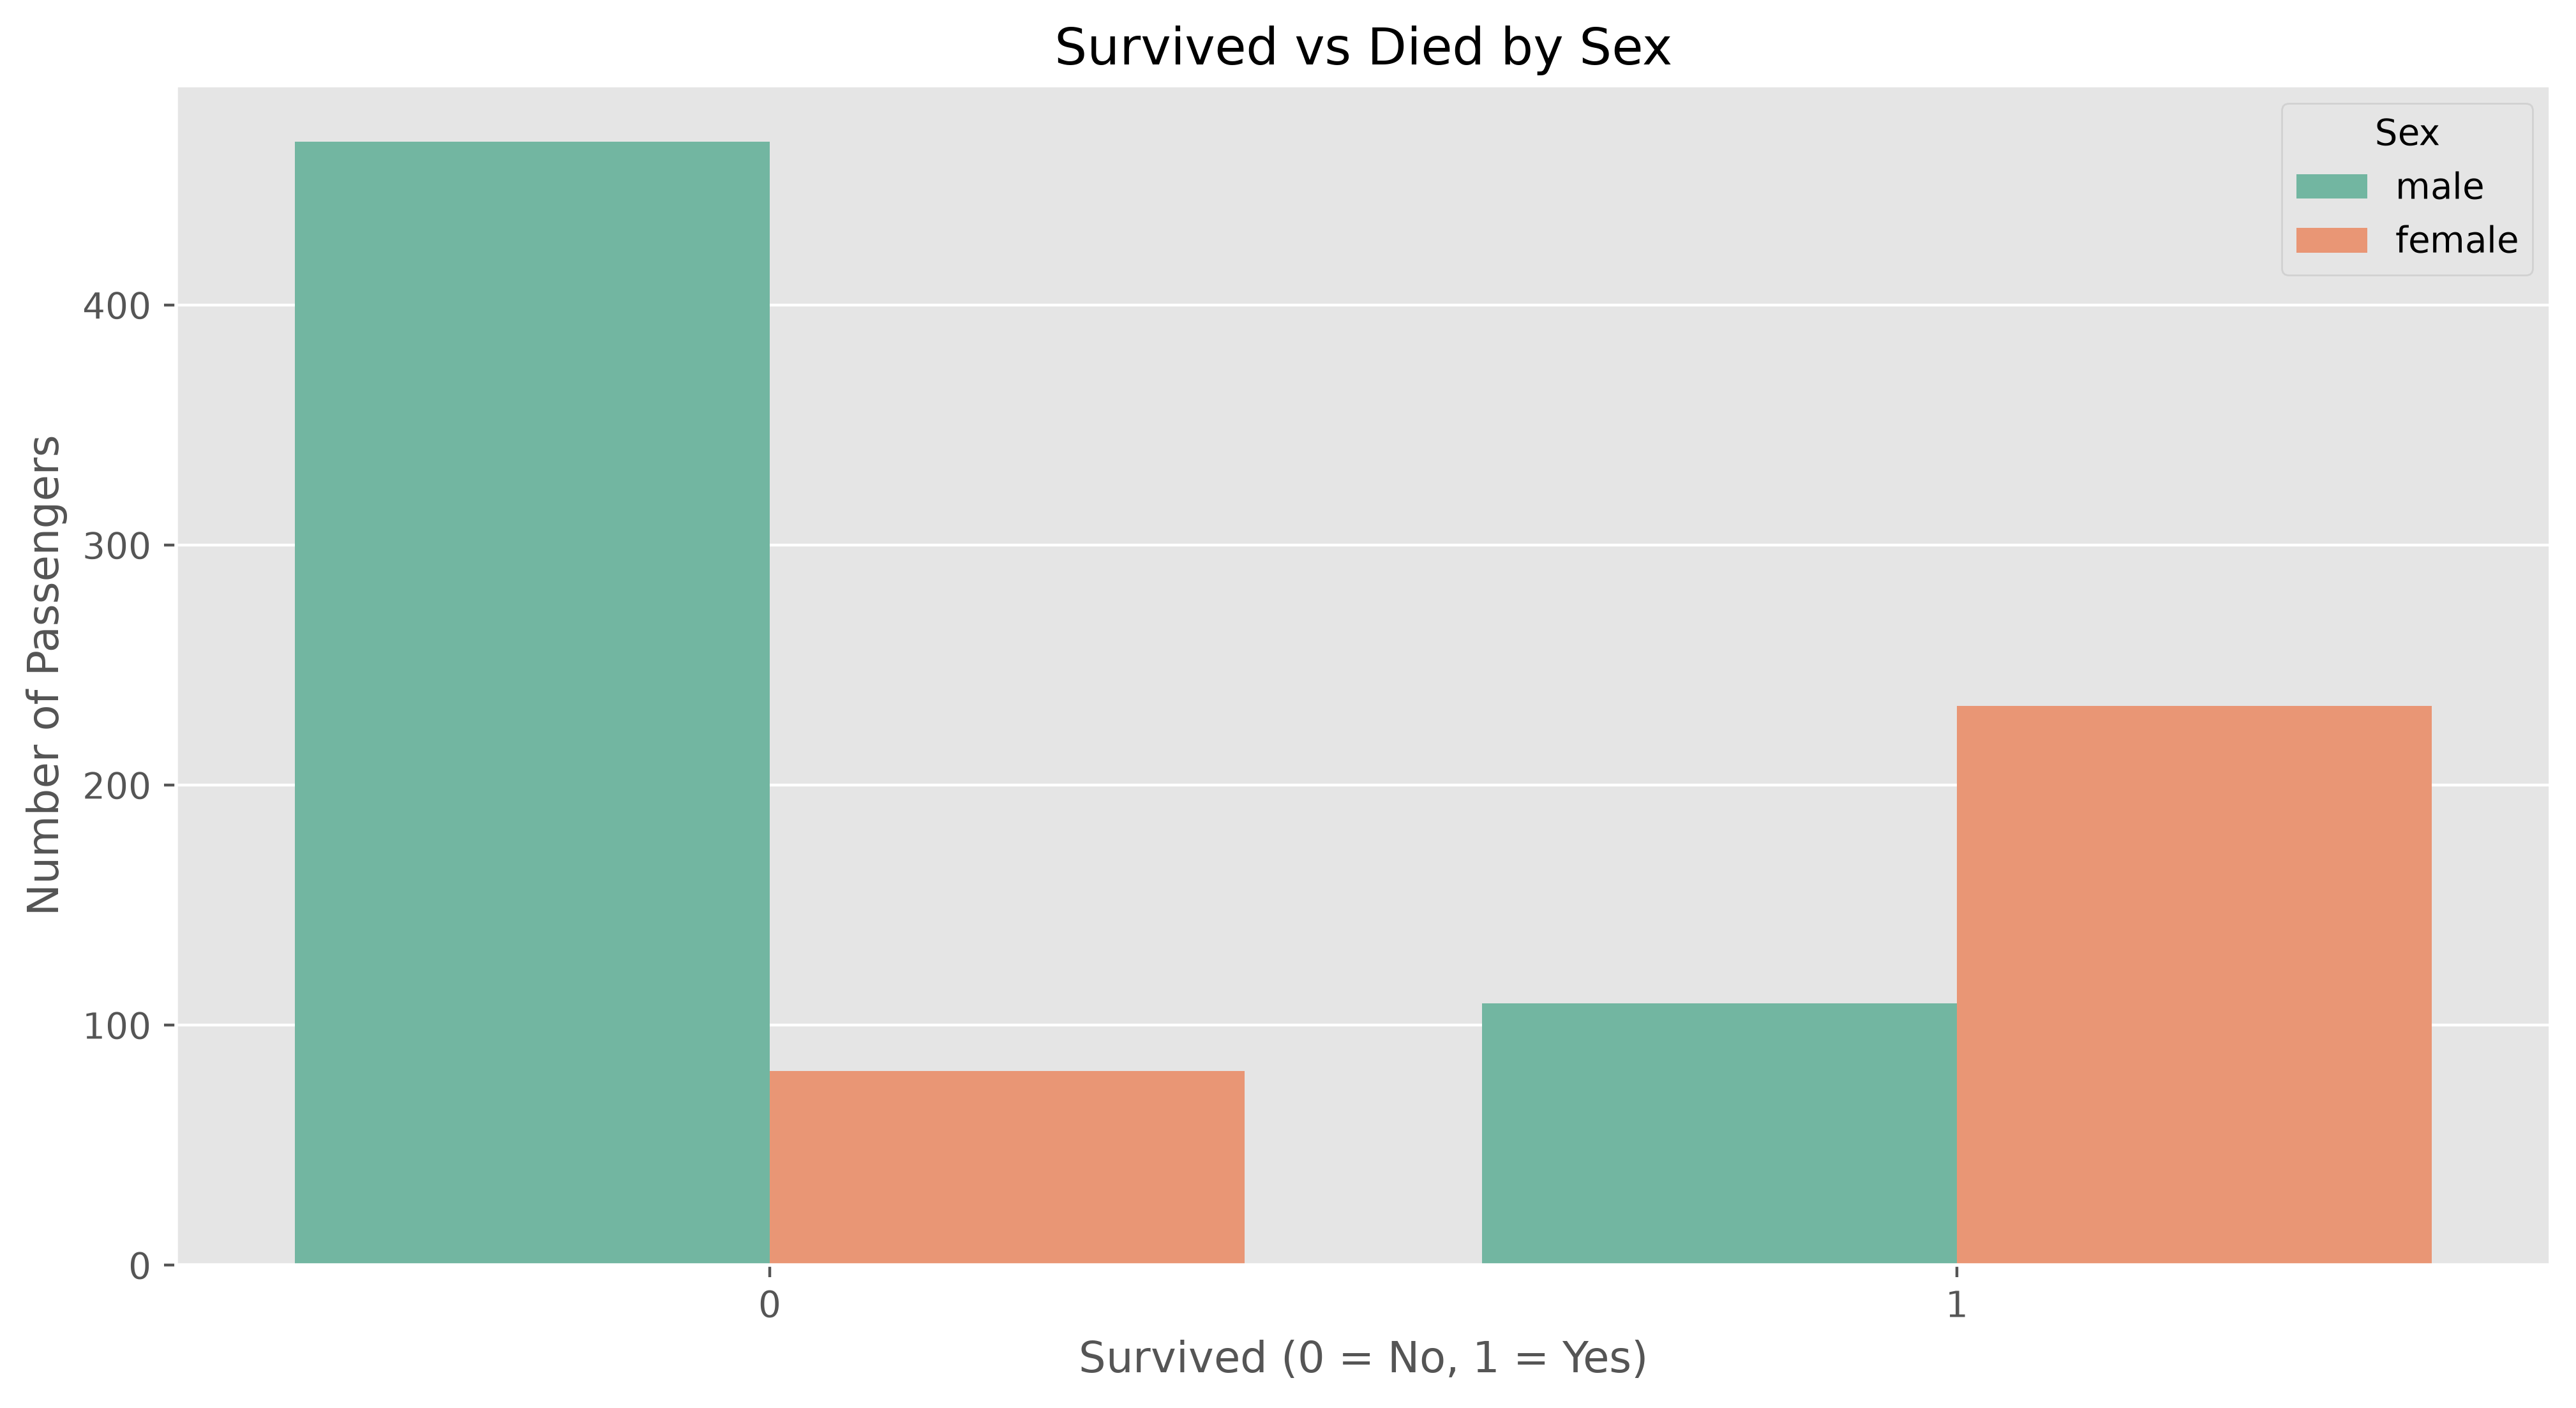

In [ ]:
# Analysis: Survival by Sex

plt.figure(figsize=(12, 6), dpi=400)

sns.countplot(x="Survived", hue="Sex", data=titanic, palette="Set2")

plt.title("Survived vs Died by Sex")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

In [ ]:
titanic.groupby("Sex")["Survived"].value_counts()

Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64

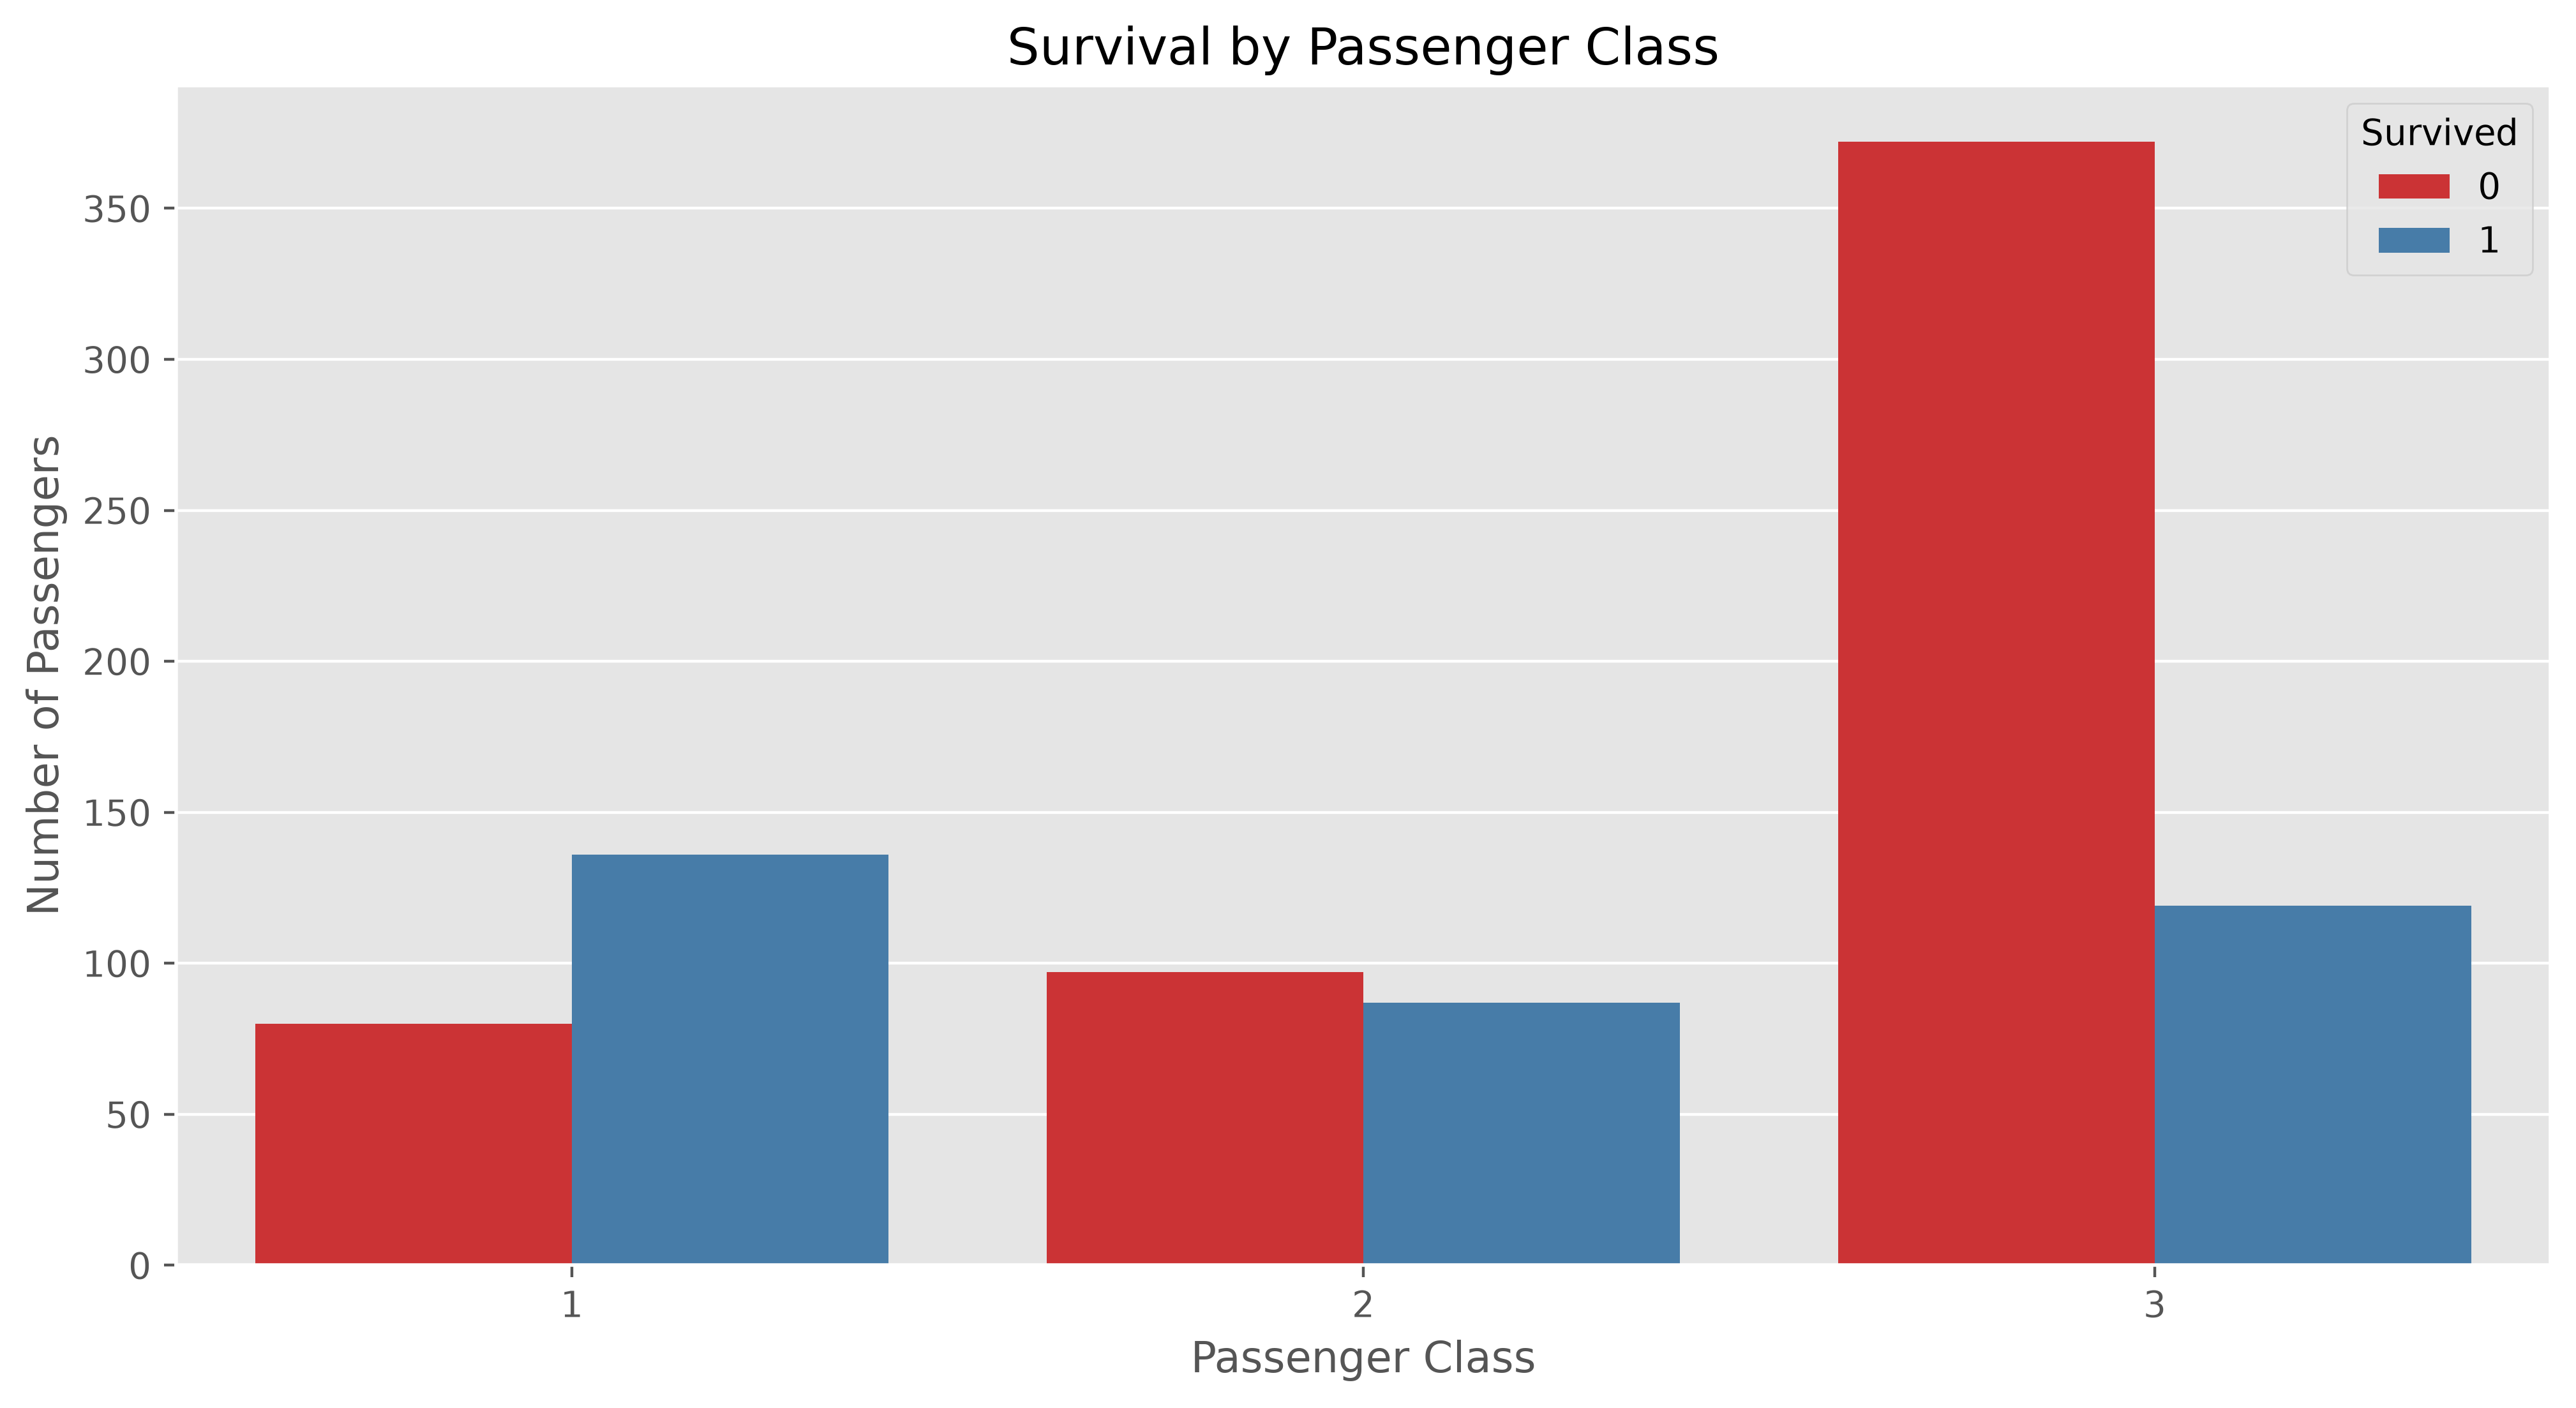

In [ ]:
# Analysis: Survival by Sex

plt.figure(figsize=(12, 6), dpi=400)

sns.countplot(x="Pclass", hue="Survived", data=titanic, palette="Set1")

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

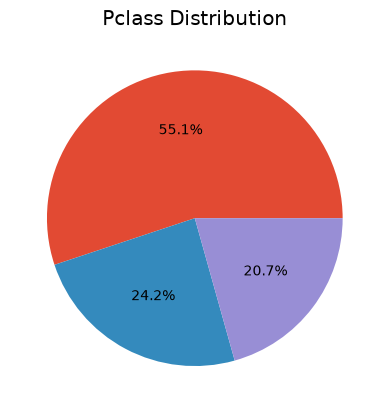

In [ ]:
plt.pie(titanic["Pclass"].value_counts(), autopct="%1.1f%%")
plt.title("Pclass Distribution")
plt.show()

In [ ]:
svl_rate = titanic.groupby("Pclass")["Survived"].value_counts(normalize=True)
svl_rate

Pclass  Survived
1       1           0.629630
        0           0.370370
2       0           0.527174
        1           0.472826
3       0           0.757637
        1           0.242363
Name: proportion, dtype: float64

In [ ]:
svl_rate.sort_index(inplace=True)
svl_rate

Pclass  Survived
1       0           0.370370
        1           0.629630
2       0           0.527174
        1           0.472826
3       0           0.757637
        1           0.242363
Name: proportion, dtype: float64

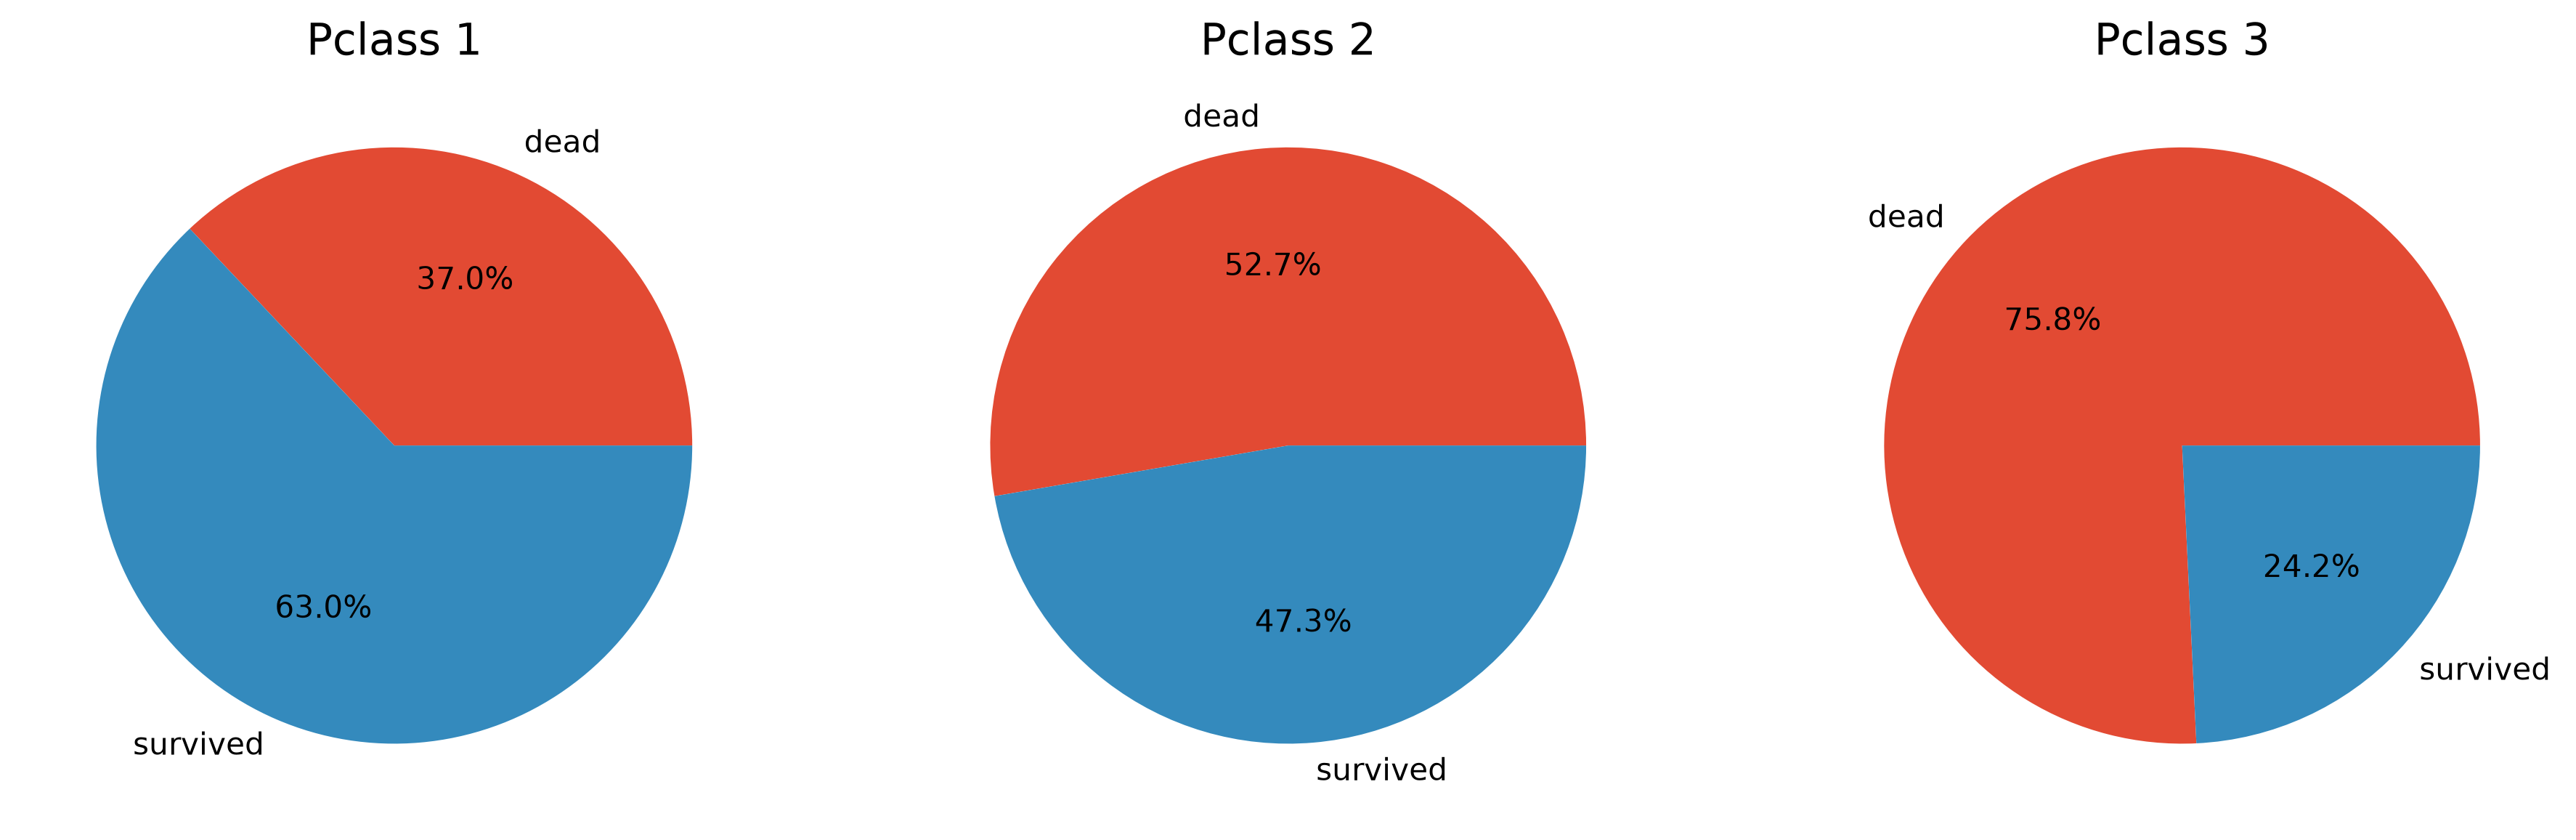

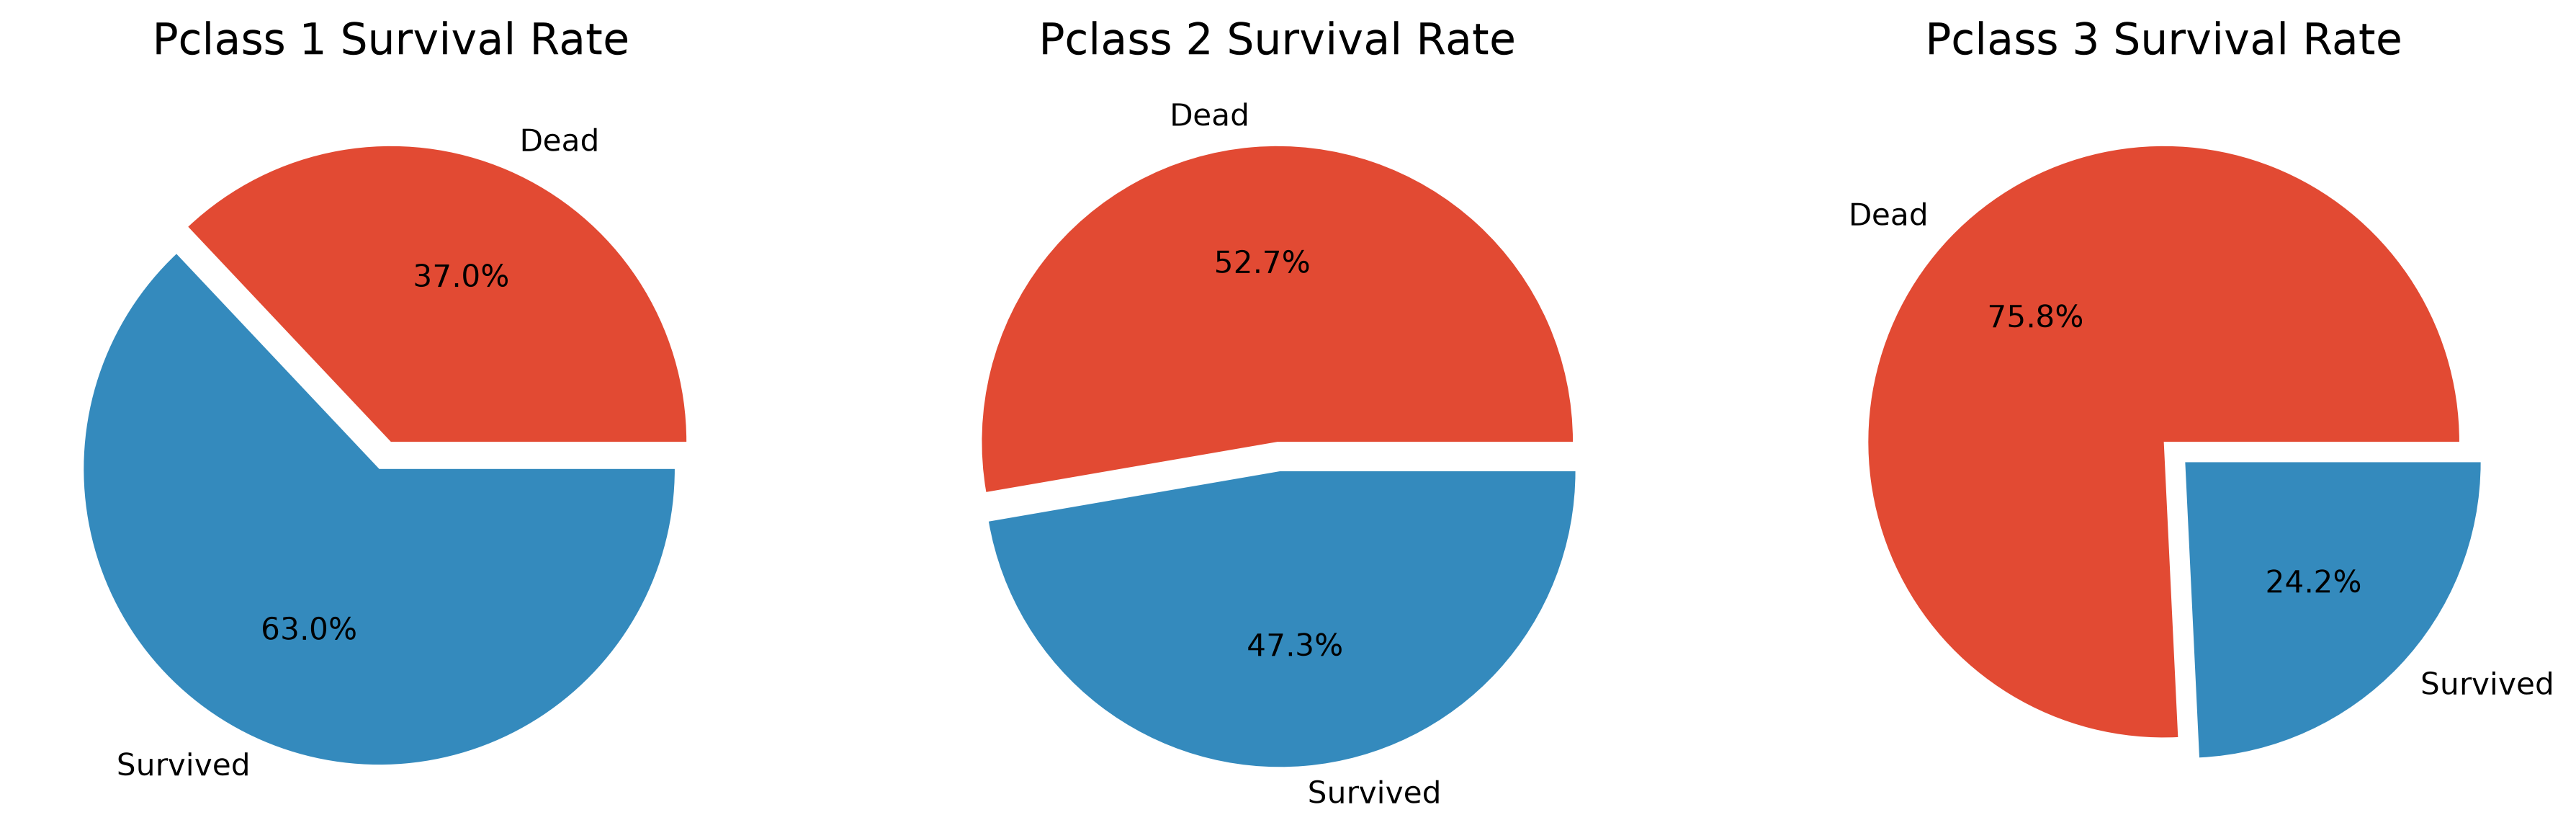

In [47]:
pclass1 = svl_rate[1]
pclass2 = svl_rate[2]
pclass3 = svl_rate[3]

labels = ["Dead", "Survived"]

plt.figure(figsize=(15, 5), dpi=300)

plt.subplot(1, 3, 1)
plt.pie(pclass1, labels=labels, autopct="%1.1f%%", explode=[0, 0.1])
plt.title("Pclass 1 Survival Rate")

plt.subplot(1, 3, 2)
plt.pie(pclass2, labels=labels, autopct="%1.1f%%", explode=[0, 0.1])
plt.title("Pclass 2 Survival Rate")

plt.subplot(1, 3, 3)
plt.pie(pclass3, labels=labels, autopct="%1.1f%%", explode=[0, 0.1])
plt.title("Pclass 3 Survival Rate")

plt.show()